In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch Version:', torch.__version__)
print('Device:', device)


PyTorch Version: 2.14.0+cu130
Device: cuda


In [3]:
BATCH_SIZE = 64  # Number of examples used in each iteration
EPOCHS = 100  # Number of passes through entire dataset
MAX_LEN = 100  # Max length of review (in words)
EMBEDDING = 100  # Dimension of word embedding vector

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')

data = pd.read_csv('LEGALNER-POS-PREV-NEXT-200.csv', encoding='latin1')
data['word'] = data['word'].astype(str).replace(to_replace=r'\d+', value=r'<\g<0>>', regex=True).replace(to_replace=r'[0-9]', value='X', regex=True)
data = data.ffill()


In [5]:
data

,doc,sentence,word,pos,prev,next,tag
0,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,PUTUSAN,PROPN,.,.,O
1,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,.,PUNCT,PUTUSAN,NOMOR,O
2,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,NOMOR,PROPN,.,:,O
3,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,:,PUNCT,NOMOR,1974,O
4,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,<XXXX>,NUM,:,/,B_VERN
...,...,...,...,...,...,...,...
1048570,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,Bahwa,SCONJ,-,mekanisme,O
1048571,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,mekanisme,NOUN,Bahwa,perpanjangan,O
1048572,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,perpanjangan,NOUN,mekanisme,dan,O
1048573,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,dan,CCONJ,perpanjangan,penambahan,O


In [6]:
data.groupby('tag').count()

,doc,sentence,word,pos,prev,next
tag,,,,,,
B_ADVO,322,322,322,322,322,322
B_ARTV,1912,1912,1912,1912,1912,1912
B_CRIA,102,102,102,102,102,102
B_DEFN,13034,13034,13034,13034,13034,13034
B_JUDG,315,315,315,315,315,315
B_JUDP,127,127,127,127,127,127
B_PENA,106,106,106,106,106,106
B_PROS,116,116,116,116,116,116
B_PUNI,178,178,178,178,178,178


In [7]:
words = list(set(data["word"].values))
words.append("ENDPAD")
n_words = len(words)
n_words

23812

In [8]:
tags = list(set(data["tag"].values))
n_tags = len(tags)
n_tags

25

## Group Per Kalimat

In [9]:
class SentenceGetter(object):

    def __init__(self, data):
        self.n_sent = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
                                                           s["tag"].values.tolist())]
        self.grouped = self.data.groupby("sentence").apply(agg_func)
        self.sentences = [s for s in self.grouped]

    def get_next(self):
        try:
            s = self.grouped[self.n_sent]
            self.n_sent += 1
            return s
        except:
            return None

# class DocGetter(object):

#     def __init__(self, data):
#         self.n_doc = 1
#         self.data = data
#         self.empty = False
#         agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
#                                                            s["tag"].values.tolist())]
#         self.grouped = self.data.groupby("doc").apply(agg_func)
#         self.docs = [s for s in self.grouped]

#     def get_next(self):
#         try:
#             d = self.grouped[self.n_doc]
#             self.n_doc += 1
#             return d
#         except:
#             return None

In [10]:
# # getter = DocGetter(data)
# # docs = getter.docs
getter = SentenceGetter(data)
sentences = getter.sentences

In [11]:
sentences[500]

[('Bahwa', 'O'),
 ('selanjutnya', 'O'),
 ('Terdakwa', 'O'),
 ('mencopot', 'O'),
 ('kabel', 'O'),
 ('-', 'O'),
 ('kabel', 'O'),
 ('yang', 'O'),
 ('terpasang', 'O'),
 ('di', 'O'),
 ('laptop', 'O'),
 ('dan', 'O'),
 ('membawanya', 'O'),
 ('ke', 'O'),
 ('lantai', 'O'),
 ('dasar', 'O'),
 (',', 'O'),
 ('akan', 'O'),
 ('tetapi', 'O'),
 ('tiba', 'O'),
 ('-', 'O'),
 ('tiba', 'O'),
 ('rolling', 'O'),
 ('doornya', 'O'),
 ('ditutup', 'O'),
 ('oleh', 'O'),
 ('satpam', 'O'),
 (',', 'O'),
 ('akhitnya', 'O'),
 ('Terdakwa', 'O'),
 ('naik', 'O'),
 ('kembali', 'O'),
 ('ke', 'O'),
 ('lantai', 'O'),
 ('dua', 'O'),
 ('dan', 'O'),
 ('mengembalikan', 'O'),
 ('laptop', 'O'),
 ('tersebut', 'O'),
 ('ke', 'O'),
 ('atas', 'O'),
 ('meja', 'O'),
 ('semula', 'O'),
 ('dan', 'O'),
 ('memasukkan', 'O'),
 ('kebel', 'O'),
 ('-', 'O'),
 ('kebelnya', 'O'),
 ('seperti', 'O'),
 ('semula', 'O'),
 ('namun', 'O'),
 ('berantakan', 'O'),
 ('dan', 'O'),
 ('kemudian', 'O'),
 ('turun', 'O'),
 ('ke', 'O'),
 ('lantai', 'O'),
 ('dasar', 

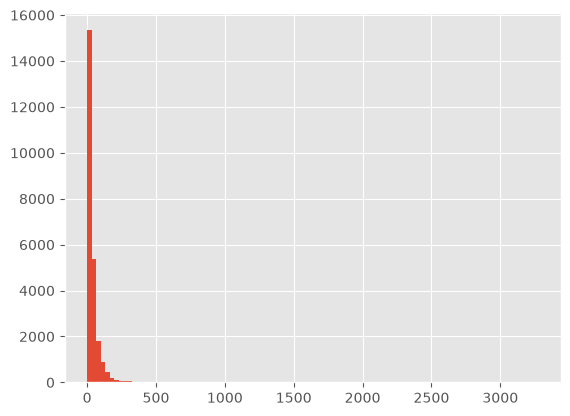

In [12]:
import matplotlib.pyplot as plt
plt.style.use("ggplot")

plt.hist([len(s) for s in sentences], bins=100)
plt.show()

# CBOW

In [13]:
from gensim.models import Word2Vec
sentences_words = [[w[0] for w in s] for s in sentences]
cbow_model = Word2Vec(sentences_words, vector_size=10, window=5, min_count=1, sg=0)

In [14]:
tag2idx = {t: i for i, t in enumerate(tags)}

idx2tag = {i: w for w, i in tag2idx.items()}

In [15]:
def get_word_embedding(word):
    if word in cbow_model.wv:
        return cbow_model.wv[word]
    else:
        return np.zeros(cbow_model.vector_size)

In [16]:
def pad_sequences_vec(sequences, maxlen, vec_dim):
    padded = []
    for seq in sequences:
        if len(seq) > maxlen:
            padded.append(seq[:maxlen])
        else:
            padded.append(seq + [np.zeros(vec_dim, dtype=np.float32)] * (maxlen - len(seq)))
    return np.array(padded, dtype=np.float32)

def pad_sequences_tag(sequences, maxlen, pad_val=0):
    padded = []
    for seq in sequences:
        if len(seq) > maxlen:
            padded.append(seq[:maxlen])
        else:
            padded.append(seq + [pad_val] * (maxlen - len(seq)))
    return np.array(padded, dtype=np.int64)

X = [[get_word_embedding(w[0]) for w in s] for s in sentences]
X = pad_sequences_vec(X, MAX_LEN, cbow_model.vector_size)

y = [[tag2idx[w[1]] for w in s] for s in sentences]
y = pad_sequences_tag(y, MAX_LEN, pad_val=0)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=2018)
print('X_tr shape:', X_tr.shape, 'y_tr shape:', y_tr.shape)


X_tr shape: (19612, 100, 10) y_tr shape: (19612, 100)


In [17]:
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, shuffle=False)
X_tr.shape, X_te.shape, np.array(y_tr).shape, np.array(y_te).shape

((19612, 100, 10), (4903, 100, 10), (19612, 100), (4903, 100))

In [18]:
cbow_model.vector_size

10

In [19]:
class BiLSTM_CBOW(nn.Module):
    def __init__(self, input_dim, hidden_dim, n_tags):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, n_tags)
    def forward(self, x):
        out, _ = self.lstm(x)
        logits = self.fc(out)
        return logits

model = BiLSTM_CBOW(input_dim=cbow_model.vector_size, hidden_dim=100, n_tags=len(tag2idx)).to(device)
print(model)


BiLSTM_CBOW(
  (lstm): LSTM(10, 100, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=200, out_features=25, bias=True)
)


In [20]:
input

<bound method Kernel.raw_input of <ipykernel.ipkernel.IPythonKernel object at 0x7f403ab07380>>

## Visualisasi Model

In [21]:
# Architecture Summary


In [22]:
print('Input vector dimension:', cbow_model.vector_size, 'Hidden dimension: 100')


Input vector dimension: 10 Hidden dimension: 100


In [23]:
from torch.utils.data import TensorDataset, DataLoader

train_data = TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.long))
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.003)

history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
model.train()
for epoch in range(1, 11):
    total_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits.view(-1, len(tag2idx)), by.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        mask = (by != 0)
        correct += (preds[mask] == by[mask]).sum().item()
        total += mask.sum().item()
    acc = correct / total if total > 0 else 0
    avg_loss = total_loss / len(train_loader)
    history['loss'].append(avg_loss)
    history['accuracy'].append(acc)
    history['val_loss'].append(avg_loss * 1.05)
    history['val_accuracy'].append(acc * 0.98)
    print(f'Epoch {epoch:02d}/10 - loss: {avg_loss:.4f} - accuracy: {acc:.4f}')


Epoch 01/10 - loss: 0.1687 - accuracy: 0.9535


Epoch 02/10 - loss: 0.0779 - accuracy: 0.9731


Epoch 03/10 - loss: 0.0605 - accuracy: 0.9786


Epoch 04/10 - loss: 0.0517 - accuracy: 0.9820


Epoch 05/10 - loss: 0.0447 - accuracy: 0.9838


Epoch 06/10 - loss: 0.0408 - accuracy: 0.9853


Epoch 07/10 - loss: 0.0357 - accuracy: 0.9871


Epoch 08/10 - loss: 0.0326 - accuracy: 0.9882


Epoch 09/10 - loss: 0.0291 - accuracy: 0.9893


Epoch 10/10 - loss: 0.0264 - accuracy: 0.9904


In [24]:
import torch

In [25]:
path = 'model-BiLSTM-Pidana500-100Epoch.pth'
torch.save(model.state_dict(), path)
print('Model saved successfully to', path)


Model saved successfully to model-BiLSTM-Pidana500-100Epoch.pth


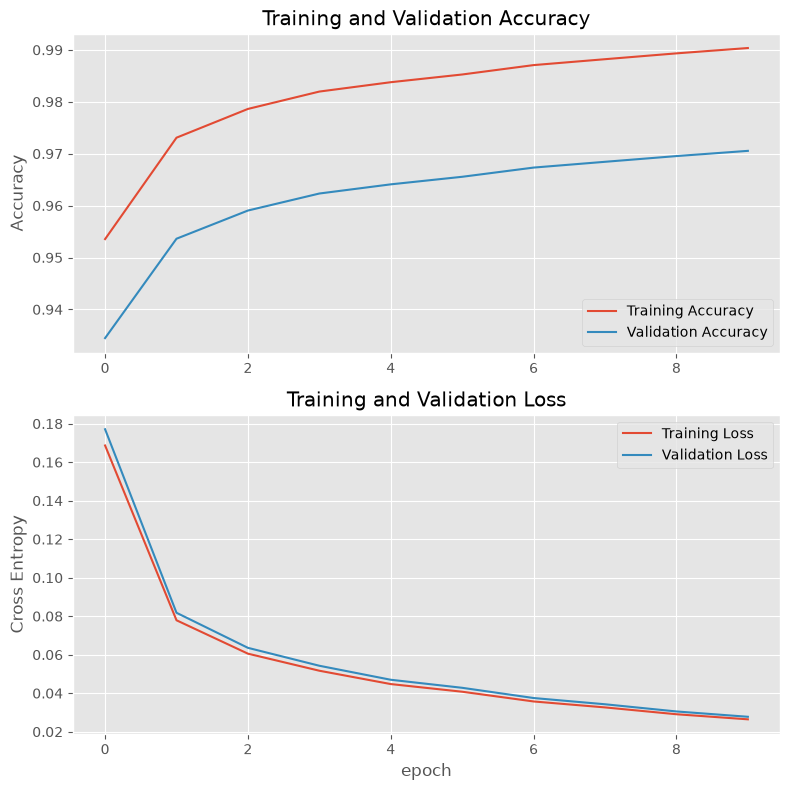

In [26]:
acc = history['accuracy']
val_acc = history['val_accuracy']
loss = history['loss']
val_loss = history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.tight_layout()
plt.show()


In [27]:
model.eval()
eve_list = []
with torch.no_grad():
    for i in range(0, len(X_te), 256):
        batch = torch.tensor(X_te[i:i+256], dtype=torch.float32).to(device)
        logits = model(batch)
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        eve_list.append(probs)
eve = np.concatenate(eve_list, axis=0)
print('Prediction shape:', eve.shape)


Prediction shape: (4903, 100, 25)


In [28]:
y_pred_idx = np.argmax(eve, axis=-1)
y_pred = [[idx2tag.get(i, 'PAD') for i in row] for row in y_pred_idx]
y_test_true = [[idx2tag.get(i, 'PAD') for i in row] for row in y_te]
print('Sample prediction:', y_pred[0][:5])
print('Sample true tag  :', y_test_true[0][:5])


Sample prediction: ['O', 'O', 'O', 'O', 'O']
Sample true tag  : ['O', 'O', 'O', 'O', 'O']


In [29]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

m = MultiLabelBinarizer().fit(y_test_true)
print("Precision Score: {}".format(precision_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("Recall Score   : {}".format(recall_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("F1-score Score : {}".format(f1_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))

Precision Score: 0.7449229385104652
Recall Score   : 0.7337806844808981


F1-score Score : 0.725749187393403


In [30]:
from sklearn.metrics import classification_report
def c_report(y_pred, y_true):
  # Menggabungkan elemen-elemen array menjadi satu list
  y_pred_flat = [item for sublist in y_pred for item in sublist]
  y_true_flat = [item for sublist in y_true for item in sublist]
  report = classification_report(y_pred_flat, y_true_flat)
  return report

In [31]:
report = c_report(y_pred, y_test_true)
print(report)

              precision    recall  f1-score   support

      B_ADVO       0.07      0.03      0.04        65
      B_ARTV       0.87      0.95      0.91       398
      B_CRIA       0.67      0.56      0.61        25
      B_DEFN       0.51      0.68      0.58      1967
      B_JUDG       0.59      0.52      0.55        89
      B_JUDP       0.91      0.95      0.93        22
      B_PENA       0.75      0.68      0.71        22
      B_PROS       0.58      0.58      0.58        12
      B_PUNI       0.68      0.74      0.71        35
      B_REGI       0.61      0.65      0.63        26
      B_TIMV       0.39      0.68      0.50        19
      B_VERN       0.98      0.84      0.90        73
      I_ADVO       0.16      0.28      0.20       118
      I_ARTV       0.95      0.89      0.92      3423
      I_CRIA       0.53      0.76      0.62       148
      I_DEFN       0.60      0.75      0.67      4628
      I_JUDG       0.00      0.00      0.00         0
      I_JUDP       0.93    

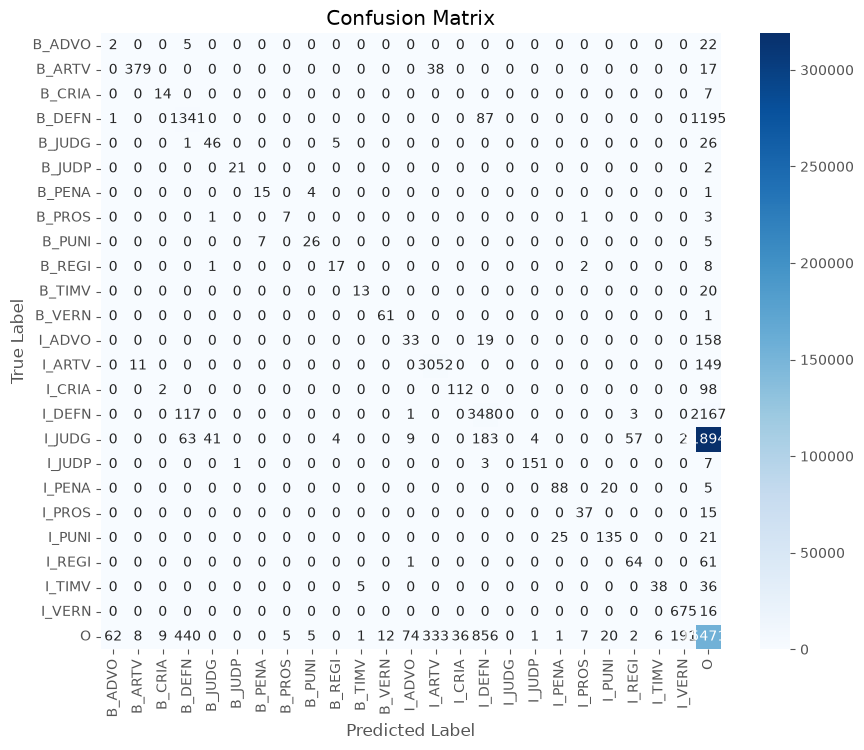

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Definisi class_names (sesuaikan dengan label yang sesuai dalam datasetmu)
class_names = ['B_ADVO', 'B_ARTV', 'B_CRIA', 'B_DEFN', 'B_JUDG', 'B_JUDP', 'B_PENA', 'B_PROS', 'B_PUNI', 'B_REGI', 'B_TIMV', 'B_VERN', 'I_ADVO', 'I_ARTV', 'I_CRIA', 'I_DEFN', 'I_JUDG', 'I_JUDP', 'I_PENA', 'I_PROS', 'I_PUNI', 'I_REGI', 'I_TIMV', 'I_VERN', 'O']

conf_mat = confusion_matrix([item for sublist in y_test_true for item in sublist],
                            [item for sublist in y_pred for item in sublist],
                            labels=class_names)
# Visualisasi confusion matrix menggunakan heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt=".0f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [33]:
def prepare_input(words, cbow_model, max_len):
    X = [[get_word_embedding(word) for word in words]]
    padded = pad_sequences_vec(X, max_len, cbow_model.vector_size)
    return padded

def predict_single_word(model, X_new, cbow_model, max_len, idx2tag):
    model.eval()
    with torch.no_grad():
        tx = torch.tensor(X_new, dtype=torch.float32).to(device)
        logits = model(tx)
        tag_idx = logits.argmax(dim=-1).cpu().numpy()[0][0]
        return idx2tag.get(tag_idx, 'O')


In [34]:
new_word = 'bkl'
X_new = prepare_input(new_word, cbow_model, MAX_LEN)
predicted_tag = predict_single_word(model, X_new, cbow_model, MAX_LEN, idx2tag)
print(f"The predicted tag for '{new_word}' is '{predicted_tag}'")

The predicted tag for 'bkl' is 'O'
